# Сравнение обученных матриц участников

Загружаем **наш checkpoint воспроизведения LISA `repro_s42`**, обученный на всех 27 участниках и обеих сессиях, а не исходные веса автора.
По протоколу это условие `exp08_reproduction` из `experiments/exp08_09_full_lisa/protocol.json`.
Так в сравнении нет слотов людей, исключённых из обучения.

Для каждого участника сохранена матрица **`A[s]: (25, 270)`**:
она смешивает 270 входных каналов в 25 ветвей. Весь банк — **`(27, 25, 270)`**.
Загружаем только subject layer: для сравнения весов не нужны MEG-записи и создание полной LISA.

In [1]:
import json
import hashlib
from pathlib import Path

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from lisa.model.nn_modules import SubjectPlusLayer

%matplotlib inline
pd.set_option('display.max_rows', 30)

Matplotlib is building the font cache; this may take a moment.


## 1. Загружаем обученные веса

`subject_id=1` соответствует `A[0]`, ..., `subject_id=27` — `A[26]`.
В таблицах и на графиках дальше используются **ID людей 1–27**, а не индексы 0–26.
Чтобы открыть другой запуск, поменяй `run_dir`; текущий разбор рассчитан на `repro_s42` со всеми обученными слотами.

In [2]:
# Находим корень проекта и из папки notebooks, и при запуске из корня.
project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / 'code/LISA/pyproject.toml').is_file()
)
run_dir = project_root / 'outputs/full_raw/runs/repro_s42/repro_s42-25branches_b527a316'
checkpoint_path = run_dir / 'lisa_checkpoint.pt'
config = json.loads((run_dir / 'config.json').read_text())
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=True)

# Достаём только банк индивидуальных матриц из весов полной модели.
saved_A = checkpoint['model_state_dict']['spatial_module.subject_layer.A']
n_subjects, n_branches, n_input = saved_A.shape
assert tuple(saved_A.shape) == (27, 25, 270)
assert torch.isfinite(saved_A).all()

# Создание слоя нужно лишь для загрузки весов; начальные случайные веса заменяются целиком.
subject_layer = SubjectPlusLayer(n_input, n_branches, n_subjects)
subject_layer.load_state_dict({'A': saved_A}, strict=True)
subject_layer.eval()
A = subject_layer.A.detach().clone()  # (27, 25, 270), без графа градиентов.
assert torch.equal(A, saved_A)
subject_ids = np.arange(1, n_subjects + 1)

print('Checkpoint:', checkpoint_path.relative_to(project_root))
print('SHA-256:', hashlib.sha256(checkpoint_path.read_bytes()).hexdigest())
print('Банк матриц:', tuple(A.shape), '| одна матрица:', tuple(A[0].shape))
display(pd.DataFrame([{
    'run_group': config['run_group'],
    'seed': config['seed'],
    'attention': config['use_spatial_attention'],
    'branches': config['n_channels_unmix'],
    'temporal_blocks': config['n_temporal_module_blocks'],
    'checkpoint_epoch_index': checkpoint['epoch'],  # В Trainer нумерация начинается с 0.
    'epoch_number': checkpoint['epoch'] + 1,
    'validation_loss': checkpoint['loss_val'],
}]))

Checkpoint: outputs/full_raw/runs/repro_s42/repro_s42-25branches_b527a316/lisa_checkpoint.pt
SHA-256: b344bedac6ca4549e485b1d862469af6bdb2635b3949e05cce883ba3fa86017d
Банк матриц: (27, 25, 270) | одна матрица: (25, 270)


,run_group,seed,attention,branches,temporal_blocks,checkpoint_epoch_index,epoch_number,validation_loss
0,repro_s42,42,3D,25,2,9,10,0.447281


## 2. Чем отличаются матрицы всех участников

Для сравнения разворачиваем каждую матрицу `25 × 270` в вектор из **6750 весов**.

- **Норма Фробениуса** — корень из суммы квадратов всех весов: величина матрицы.
- **Косинусная близость** — насколько совпадают направления двух векторов весов: `1` — одно направление, `0` — ортогональные, `−1` — противоположные. Это не коэффициент корреляции.
- **Расстояние Фробениуса** `||A_i − A_j||` — абсолютная величина различия, учитывает и направление, и масштаб.

Мы сравниваем матрицы **внутри одного checkpoint**, в одном внутреннем базисе каналов.

In [3]:
flat = A.flatten(start_dim=1).double()  # (27, 6750).
norms = flat.norm(dim=1)                # По одной норме на участника.
assert (norms > 0).all()

unit = F.normalize(flat, dim=1)
cosine = unit @ unit.T                  # (27, 27), все пары участников.
distance = torch.cdist(
    flat, flat, p=2, compute_mode='donot_use_mm_for_euclid_dist'
)

# Среднее здесь — обычное арифметическое среднее весов, не обученная shared-матрица.
mean_A = A.mean(dim=0)
distance_to_mean = (A.double() - mean_A.double()).flatten(1).norm(dim=1)
other_cosine_mean = (cosine.sum(dim=1) - cosine.diag()) / (n_subjects - 1)

subject_summary = pd.DataFrame({
    'subject_id': subject_ids,
    'matrix_norm': norms.numpy(),
    'distance_to_mean_matrix': distance_to_mean.numpy(),
    'mean_cosine_to_other_subjects': other_cosine_mean.numpy(),
}).set_index('subject_id')
display(subject_summary.round(4))

# Проверяем смысл диагонали и симметрию, чтобы не включить сравнение человека с собой.
torch.testing.assert_close(cosine.diag(), torch.ones(n_subjects, dtype=torch.float64))
torch.testing.assert_close(distance.diag(), torch.zeros(n_subjects, dtype=torch.float64))
torch.testing.assert_close(cosine, cosine.T)
torch.testing.assert_close(distance, distance.T)

,matrix_norm,distance_to_mean_matrix,mean_cosine_to_other_subjects
subject_id,,,
1,4.1481,4.0469,0.0465
2,4.2663,4.0320,0.0724
3,4.3338,4.1034,0.0697
4,4.7527,4.5149,0.0633
5,4.9205,4.7357,0.0485
6,4.2439,3.9961,0.0757
7,4.7947,4.5105,0.0733
8,4.5975,4.4482,0.0472
9,4.5325,4.2768,0.0718


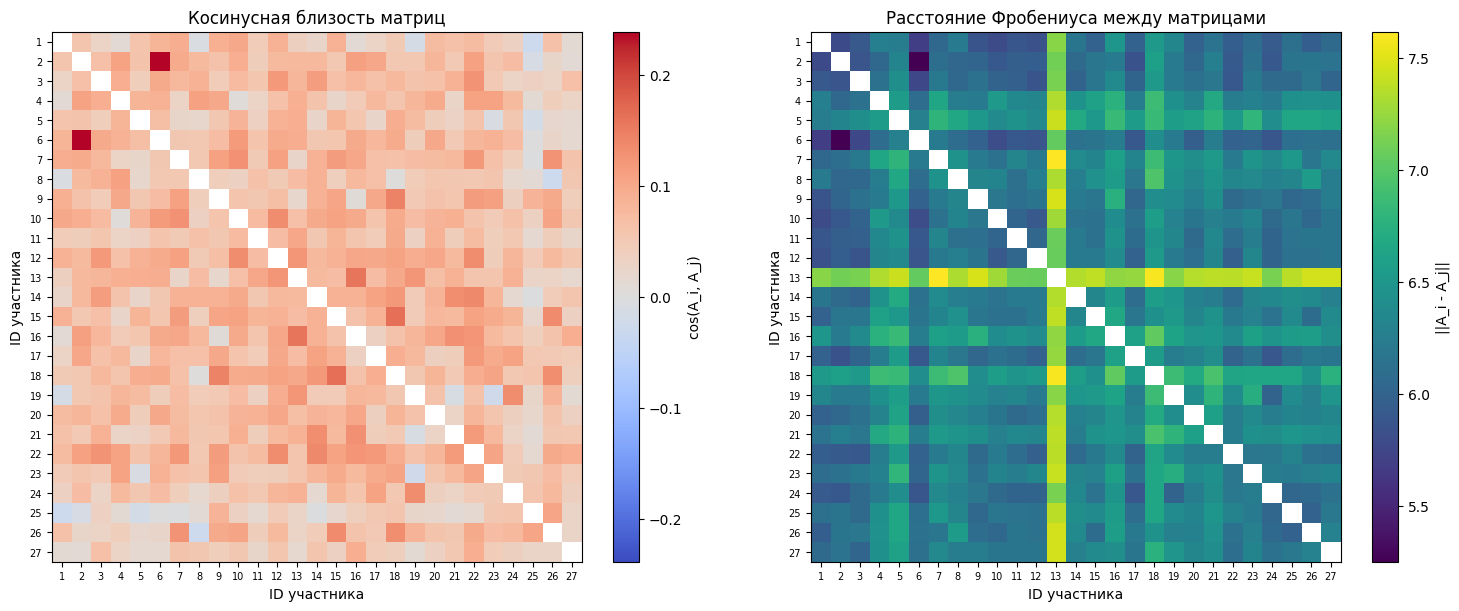

In [4]:
# Каждая строка/столбец — участник. Диагональ скрываем: это сравнение с самим собой.
cosine_plot = cosine.numpy().copy()
distance_plot = distance.numpy().copy()
np.fill_diagonal(cosine_plot, np.nan)
np.fill_diagonal(distance_plot, np.nan)
cosine_limit = float(np.nanmax(np.abs(cosine_plot)))

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
image = axes[0].imshow(cosine_plot, cmap='coolwarm', vmin=-cosine_limit, vmax=cosine_limit)
axes[0].set_title('Косинусная близость матриц')
fig.colorbar(image, ax=axes[0], label='cos(A_i, A_j)')
image = axes[1].imshow(distance_plot, cmap='viridis')
axes[1].set_title('Расстояние Фробениуса между матрицами')
fig.colorbar(image, ax=axes[1], label='||A_i - A_j||')
for ax in axes:
    ax.set_xticks(range(n_subjects), subject_ids, fontsize=7)
    ax.set_yticks(range(n_subjects), subject_ids, fontsize=7)
    ax.set_xlabel('ID участника')
    ax.set_ylabel('ID участника')
plt.show()

In [5]:
# Список уникальных пар: (1, 2) и (2, 1) считаем одной парой, диагональ исключаем.
i, j = torch.triu_indices(n_subjects, n_subjects, offset=1)
pairs = pd.DataFrame({
    'subject_a': subject_ids[i.numpy()],
    'subject_b': subject_ids[j.numpy()],
    'cosine': cosine[i, j].numpy(),
    'distance': distance[i, j].numpy(),
})
assert len(pairs) == n_subjects * (n_subjects - 1) // 2

print('5 самых похожих пар по косинусу:')
display(pairs.sort_values('cosine', ascending=False).head(5).round(4))
print('5 пар с наименьшим косинусом (это отдельная метрика от расстояния):')
display(pairs.sort_values('cosine').head(5).round(4))
print('5 ближайших пар по расстоянию Фробениуса:')
display(pairs.sort_values('distance').head(5).round(4))
print(f'Всего уникальных пар: {len(pairs)}')
print(f'Средний косинус: {pairs.cosine.mean():.4f}')
print(f'Диапазон косинуса: {pairs.cosine.min():.4f} ... {pairs.cosine.max():.4f}')

5 самых похожих пар по косинусу:


,subject_a,subject_b,cosine,distance
29,2,6,0.2390,5.2496
275,15,18,0.1638,6.4382
248,13,16,0.1575,7.2208
188,9,18,0.1451,6.4094
267,14,22,0.1379,6.0782


5 пар с наименьшим косинусом (это отдельная метрика от расстояния):


,subject_a,subject_b,cosine,distance
178,8,26,-0.0273,6.5546
23,1,25,-0.0271,6.1264
318,19,23,-0.0233,6.7230
117,5,25,-0.0163,6.6522
17,1,19,-0.0131,6.3371


5 ближайших пар по расстоянию Фробениуса:


,subject_a,subject_b,cosine,distance
29,2,6,0.2390,5.2496
4,1,6,0.0825,5.6845
53,3,6,0.0978,5.7615
0,1,2,0.0565,5.7802
8,1,10,0.0999,5.8003


Всего уникальных пар: 351
Средний косинус: 0.0654
Диапазон косинуса: -0.0273 ... 0.2390


## 3. Посмотрим конкретную пару

**Поменяй два ID в следующей ячейке** и запусти её и ячейки ниже.
У матриц участников одна шкала цветов; у разности своя симметричная шкала.
Строки — 25 ветвей, столбцы — 270 входных каналов после unmixing, не физические датчики.

A[0] — участник 1: (25, 270)
A[1] — участник 2: (25, 270)
Нормы: 4.1481 и 4.2663
Косинус: 0.0565
Расстояние: 5.7802


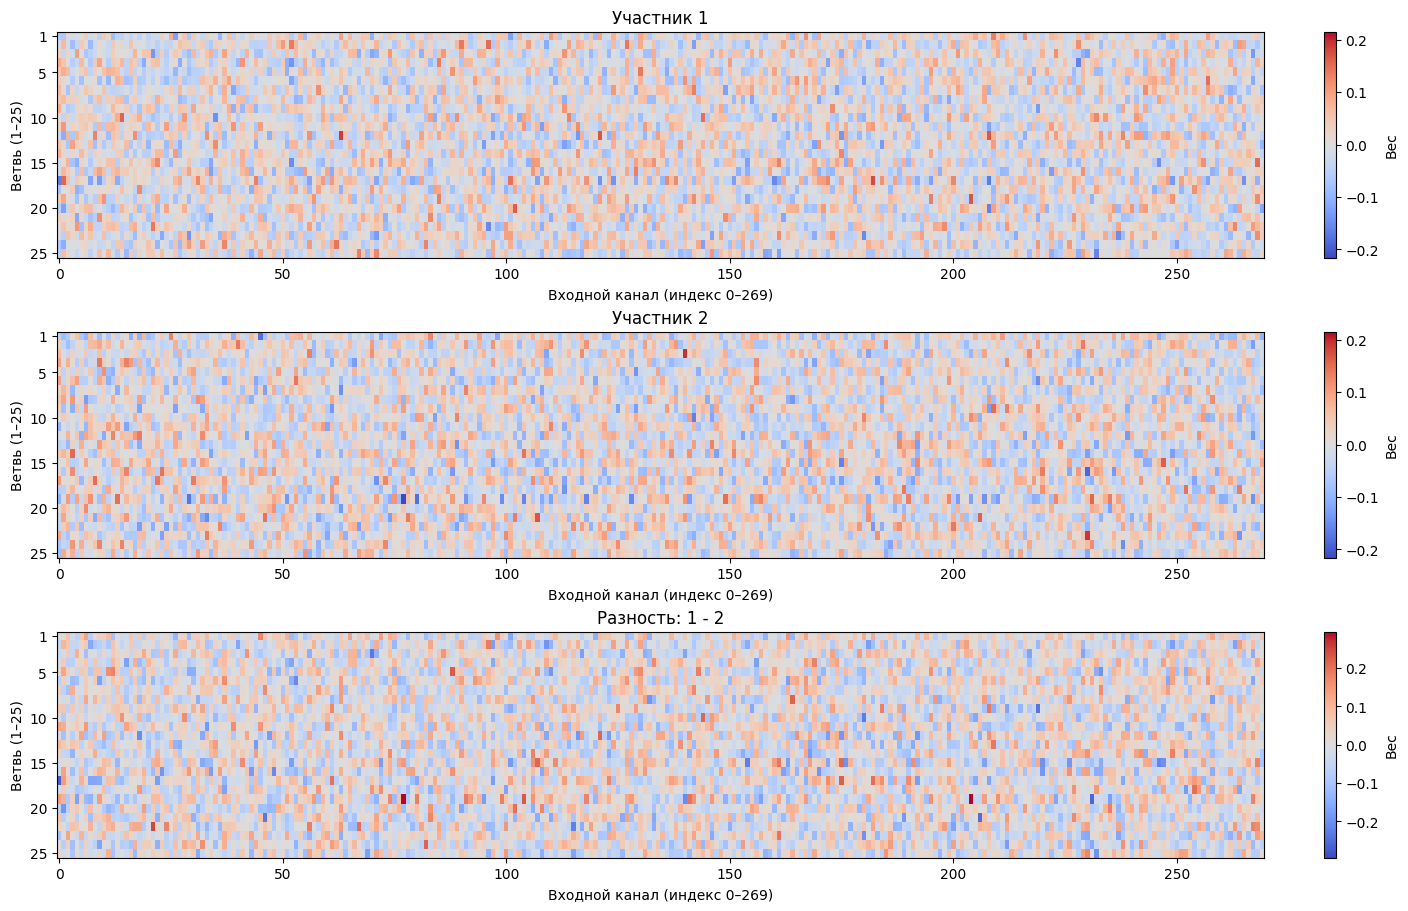

In [6]:
SUBJECT_A = 1  # ID человека 1..27, не индекс матрицы.
SUBJECT_B = 2
assert 1 <= SUBJECT_A <= n_subjects and 1 <= SUBJECT_B <= n_subjects
assert SUBJECT_A != SUBJECT_B

matrix_a = A[SUBJECT_A - 1]
matrix_b = A[SUBJECT_B - 1]
difference = matrix_a - matrix_b

print(f'A[{SUBJECT_A - 1}] — участник {SUBJECT_A}: {tuple(matrix_a.shape)}')
print(f'A[{SUBJECT_B - 1}] — участник {SUBJECT_B}: {tuple(matrix_b.shape)}')
print(f'Нормы: {matrix_a.norm():.4f} и {matrix_b.norm():.4f}')
print(f'Косинус: {cosine[SUBJECT_A - 1, SUBJECT_B - 1]:.4f}')
print(f'Расстояние: {difference.norm():.4f}')

weight_limit = float(torch.stack([matrix_a.abs().max(), matrix_b.abs().max()]).max())
diff_limit = max(float(difference.abs().max()), 1e-12)
fig, axes = plt.subplots(3, 1, figsize=(14, 9), constrained_layout=True)
for ax, matrix, title, limit in zip(
    axes,
    [matrix_a, matrix_b, difference],
    [f'Участник {SUBJECT_A}', f'Участник {SUBJECT_B}', f'Разность: {SUBJECT_A} - {SUBJECT_B}'],
    [weight_limit, weight_limit, diff_limit],
):
    image = ax.imshow(matrix.numpy(), aspect='auto', cmap='coolwarm', vmin=-limit, vmax=limit)
    ax.set_title(title)
    ax.set_ylabel('Ветвь (1–25)')
    ax.set_yticks([0, 4, 9, 14, 19, 24], [1, 5, 10, 15, 20, 25])
    ax.set_xlabel('Входной канал (индекс 0–269)')
    fig.colorbar(image, ax=ax, label='Вес')
plt.show()

In [7]:
# Сравниваем одинаковые номера ветвей двух участников: строка 1 с 1, ..., 25 с 25.
# Номера сохраняем: дальше в сети для каждой ветви свой общий временной фильтр.
branch_summary = pd.DataFrame({
    'branch': np.arange(1, n_branches + 1),
    f'norm_subject_{SUBJECT_A}': matrix_a.norm(dim=1).numpy(),
    f'norm_subject_{SUBJECT_B}': matrix_b.norm(dim=1).numpy(),
    'cosine_same_branch': F.cosine_similarity(matrix_a, matrix_b, dim=1).numpy(),
    'distance_same_branch': difference.norm(dim=1).numpy(),
}).set_index('branch')
display(branch_summary.round(4))

,norm_subject_1,norm_subject_2,cosine_same_branch,distance_same_branch
branch,,,,
1,0.7515,0.8821,0.2428,1.0104
2,0.7922,0.8174,0.0056,1.1351
3,0.8325,0.7923,0.0844,1.0998
4,0.8071,0.8090,0.1477,1.0550
5,0.7861,0.7849,-0.1668,1.1999
6,0.8202,0.8189,0.0203,1.1472
7,0.8183,0.7605,0.2339,0.9782
8,0.7751,0.8306,0.0164,1.1267
9,0.7449,0.8427,0.0776,1.0806


## 4. Что происходит со средней матрицей

Проверяем, насколько меняется норма при усреднении индивидуальных матриц.
Уменьшение нормы может возникать из-за взаимного погашения разных весов.
**Отношение норм не является долей общей информации или долей сохранённого качества.**

Средняя норма индивидуальных матриц: 4.6397
Норма арифметической средней матрицы: 1.4730
Отношение норм: 0.3175


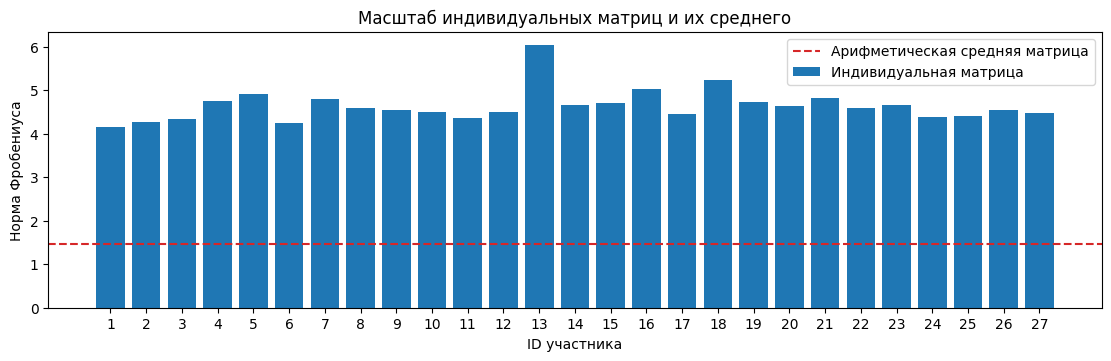

In [8]:
mean_norm = float(mean_A.norm())
average_individual_norm = float(norms.mean())
print(f'Средняя норма индивидуальных матриц: {average_individual_norm:.4f}')
print(f'Норма арифметической средней матрицы: {mean_norm:.4f}')
print(f'Отношение норм: {mean_norm / average_individual_norm:.4f}')

fig, ax = plt.subplots(figsize=(11, 3.5), constrained_layout=True)
ax.bar(subject_ids, norms.numpy(), label='Индивидуальная матрица')
ax.axhline(mean_norm, color='tab:red', linestyle='--', label='Арифметическая средняя матрица')
ax.set_xticks(subject_ids)
ax.set_xlabel('ID участника')
ax.set_ylabel('Норма Фробениуса')
ax.set_title('Масштаб индивидуальных матриц и их среднего')
ax.legend()
plt.show()

### Как читать результаты

- Норма показывает масштаб весов, косинус — совпадение направления, расстояние — абсолютное различие.
- Различия матриц сами по себе не доказывают, что слой выделил биологические особенности людей: начальные случайные матрицы тоже различаются.
- Здесь сравниваем параметры, а не ответы на реальные MEG и не качество декодирования. Для сравнения функций нужны входные сигналы и проверка на данных.
- Все матрицы взяты из одной модели; сравнивать их поэлементно с другим seed без проверки внутреннего базиса некорректно.
- Арифметическая средняя матрица здесь не обучалась как отдельный shared-путь. По этим графикам нельзя заключить, что будущая shared-матрица улучшит перенос.